## Etapa 1 - Carregar os dados

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

In [2]:
df2000 = pd.read_csv('gasolina_2000+.csv', low_memory=False)
df2010 = pd.read_csv('gasolina_2010+.csv', low_memory=False)
df = pd.concat([df2000, df2010], ignore_index=True)
df.shape

(120823, 19)

## Etapa 2 - limpar os dados

In [3]:
df['PRODUTO'] = df['PRODUTO'].str.replace('Ó', 'O')
df['PRODUTO'].value_counts()

PRODUTO
GASOLINA COMUM        23570
GLP                   23561
OLEO DIESEL           23545
ETANOL HIDRATADO      23440
GNV                   14469
OLEO DIESEL S10       11489
GASOLINA ADITIVADA      749
Name: count, dtype: int64

df = df[['DATA FINAL', 'REGIÃO', 'ESTADO', 'PRODUTO', 'PREÇO MÉDIO REVENDA']]
df = df.rename(columns={
    'DATA FINAL': 'data',
    'REGIÃO': 'regiao',
    'ESTADO': 'estado',
    'PRODUTO': 'produto',
    'PREÇO MÉDIO REVENDA': 'preco'
})
df.head()

In [5]:
df['data'] = pd.to_datetime(df['data'])
df['preco'] = pd.to_numeric(df['preco'], errors='coerce')
df['ano'] = df['data'].dt.year
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120823 entries, 0 to 120822
Data columns (total 6 columns):
 #   Column   Non-Null Count   Dtype         
---  ------   --------------   -----         
 0   data     120823 non-null  datetime64[us]
 1   regiao   120823 non-null  str           
 2   estado   120823 non-null  str           
 3   produto  120823 non-null  str           
 4   preco    120823 non-null  float64       
 5   ano      120823 non-null  int32         
dtypes: datetime64[us](1), float64(1), int32(1), str(3)
memory usage: 5.1 MB


## Etapa 3 - Guardar no banco SQL

In [6]:
conn = sqlite3.connect('combustiveis.db')
df.to_sql('precos', conn, if_exists='replace', index=False)

120823

## Etapa 4 - Perguntas em SQL

In [7]:
q1 = pd.read_sql("""
    SELECT ano, ROUND(AVG(preco), 2) AS preco_medio
    FROM precos
    WHERE produto = 'OLEO DIESEL'
    GROUP BY ano
    ORDER BY ano
""", conn)
q1

,ano,preco_medio
0,2004,1.56
1,2005,1.78
2,2006,1.93
3,2007,1.92
4,2008,2.08
5,2009,2.11
6,2010,2.06
7,2011,2.08
8,2012,2.13
9,2013,2.36


In [8]:
q2 = pd.read_sql("""
    SELECT regiao, ROUND(AVG(preco), 2) AS preco_medio
    FROM precos
    WHERE produto = 'OLEO DIESEL'
      AND ano = (SELECT MAX(ano) FROM precos)
    GROUP BY regiao
    ORDER BY preco_medio DESC
""", conn)
q2

,regiao,preco_medio
0,NORTE,4.37
1,NORDESTE,4.11
2,CENTRO OESTE,4.11
3,SUDESTE,3.97
4,SUL,3.86


In [9]:
q3 = pd.read_sql("""
    SELECT estado, regiao, ROUND(AVG(preco), 2) AS preco_medio
    FROM precos
    WHERE produto = 'OLEO DIESEL'
      AND ano = (SELECT MAX(ano) FROM precos)
    GROUP BY estado, regiao
    ORDER BY preco_medio DESC
    LIMIT 5
""", conn)
q3

,estado,regiao,preco_medio
0,ACRE,NORTE,5.19
1,AMAPA,NORTE,4.41
2,PARA,NORTE,4.41
3,RORAIMA,NORTE,4.30
4,RIO GRANDE DO NORTE,NORDESTE,4.28


## Etapa 5 - Variação do preço

In [10]:
primeiro = q1['preco_medio'].iloc[0]
ultimo = q1['preco_medio'].iloc[-1]
aumento = (ultimo / primeiro - 1) * 100

print(f"Diesel em {q1['ano'].iloc[0]}: R$ {primeiro:.2f}")
print(f"Diesel em {q1['ano'].iloc[-1]}: R$ {ultimo:.2f}")
print(f"Aumento no período: {aumento:.0f}%")

Diesel em 2004: R$ 1.56
Diesel em 2021: R$ 4.13
Aumento no período: 165%


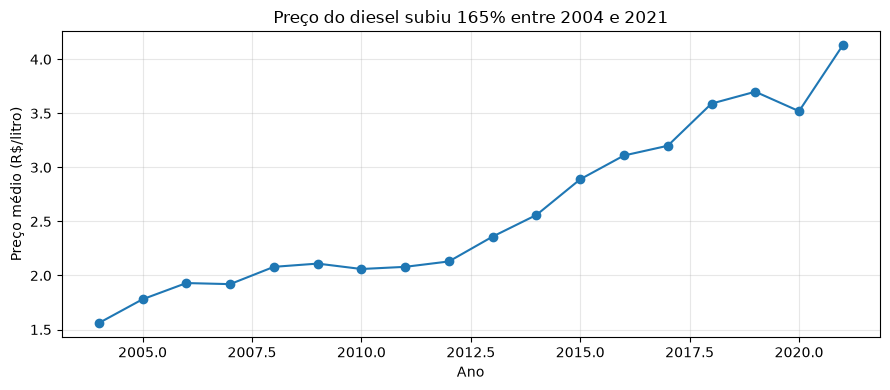

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q1['ano'], q1['preco_medio'], marker='o')
ax.set_title(f'Preço do diesel subiu {aumento:.0f}% entre 2004 e 2021')
ax.set_xlabel('Ano')
ax.set_ylabel('Preço médio (R$/litro)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('evolucao_diesel.png', dpi=150)
plt.show()

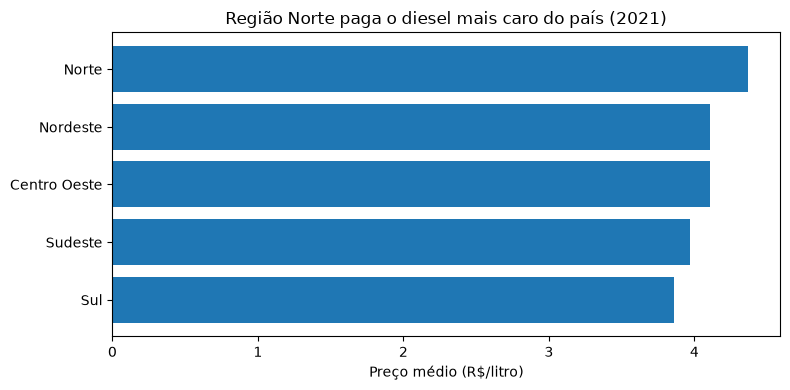

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
q2_ord = q2.sort_values('preco_medio')
ax.barh(q2_ord['regiao'].str.title(), q2_ord['preco_medio'])
ax.set_title(f"Região {q2['regiao'].iloc[0].title()} paga o diesel mais caro do país (2021)")
ax.set_xlabel('Preço médio (R$/litro)')
plt.tight_layout()
plt.savefig('diesel_por_regiao.png', dpi=150)
plt.show()

## Etapa 7 - Relatório em Excel

In [14]:
resumo = pd.DataFrame({
    'indicador': ['Preço do diesel em 2004 (R$)', 'Preço do diesel em 2021 (R$)',
                  'Aumento no período (%)', 'Região mais cara', 'Estado mais caro'],
    'valor': [primeiro, ultimo, round(aumento, 1),
              q2['regiao'].iloc[0].title(), q3['estado'].iloc[0].title()]
})

with pd.ExcelWriter('relatorio_diesel.xlsx') as writer:
    resumo.to_excel(writer, sheet_name='Resumo', index=False)
    q1.to_excel(writer, sheet_name='Evolucao anual', index=False)
    q2.to_excel(writer, sheet_name='Por regiao', index=False)
    q3.to_excel(writer, sheet_name='Top 5 estados', index=False)

resumo

,indicador,valor
0,Preço do diesel em 2004 (R$),1.56
1,Preço do diesel em 2021 (R$),4.13
2,Aumento no período (%),164.7
3,Região mais cara,Norte
4,Estado mais caro,Acre
